# Importing Libraries

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report

# Reading the Dataset

In [2]:
file_path = "/content/heart.csv"  # Change the path if it is different
df = pd.read_csv(file_path)

df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# Data Analysis

## Checking the Dataset

In [3]:
print(f"The data types for each column:\n{df.dtypes}")
print(f"\nThe shape of the dataset is: {df.shape}")
print(f"\nThe number of missing values in each column:\n{df.isnull().sum()}")

The data types for each column:
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

The shape of the dataset is: (918, 12)

The number of missing values in each column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


## Distribution of the Target Labels

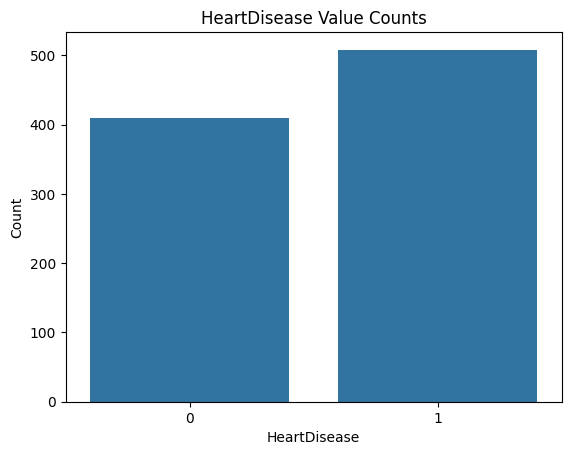

In [4]:
# Count plot of HeartDisease values
sns.countplot(x='HeartDisease', data=df)

plt.title('HeartDisease Value Counts')
plt.xlabel('HeartDisease')
plt.ylabel('Count')
plt.show()

# Encoding Categorical Features

In [5]:
categorical_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print(f"Shape after encoding: {df_encoded.shape}")
print(f"Current columns:\n{df_encoded.columns.tolist()}")

Shape after encoding: (918, 16)
Current columns:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


# Train-Test Splitting

In [6]:
feature_cols = [c for c in df_encoded.columns if c != 'HeartDisease']

X = df_encoded[feature_cols].astype(float)
y = df_encoded['HeartDisease'].astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape} | Testing set shape: {X_test.shape}")

Training set shape: (734, 15) | Testing set shape: (184, 15)


# Scaling the Columns

In [7]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

# Tasks Starts Here

## Weight Initialization

In [8]:
def init_weights(num_features, num_hidden_layer, random_seed=42):
    """
    Using Xavier initialization
    """

    random.seed(random_seed)

    W1 = [[random.gauss(0, (2.0 / num_features) ** 0.5) for _ in range(num_features)] for _ in range(num_hidden_layer)]
    b1 = [0.0] * num_hidden_layer

    W2 = [random.gauss(0, (2.0 / num_hidden_layer) ** 0.5) for _ in range(num_hidden_layer)]
    b2 = 0.0

    return W1, b1, W2, b2

## Implement the ReLU Function

In [9]:
def relu(z):
    # ------------ YOUR CODE STARTS HERE ------------
    if z > 0:
      return 1
    else:
      return 0
    # ------------ YOUR CODE ENDS HERE --------------

## Implement the Sigmoid Function

In [10]:
def sigmoid(z):
    # ------------ YOUR CODE STARTS HERE ------------
    result = 1 / (1 + math.exp(-z))
    return result
    # ------------ YOUR CODE ENDS HERE --------------

## Implement the Forward Propagation

In [11]:
def forward_prop_single(x, W1, b1, W2, b2):
    """
    Forward pass for a single sample from the dataset
    """

    num_hidden_layer = len(W1)
    num_features = len(x)

    # --- Layer 1: z1 = (W1^T)x + b1 ---
    z1 = []
    for j in range(num_hidden_layer):
        z = 0.0
        for k in range(num_features):
        # ------------ YOUR CODE STARTS HERE ------------
          z += W1[j][k] * x[k]

        z += b1[j]
        z1.append(z)
        # ------------ YOUR CODE ENDS HERE --------------


    # --- Apply ReLU ---
    a1 = [relu(z) for z in z1]


    # --- Layer 2: z2 = (W2^T)a1 + b2 ---
    z2 = 0.0
    for j in range(num_hidden_layer):
    # ------------ YOUR CODE STARTS HERE ------------
        z2 += W2[j] * a1[j]

    z2 += b2
    # ------------ YOUR CODE ENDS HERE --------------

    # --- Apply Sigmoid ---
    y_hat = sigmoid(z2)

    return z1, a1, z2, y_hat



def forward_prop(X, W1, b1, W2, b2):
    """
    Returns the predicted probabilities for all the samples in the dataset
    """
    return [forward_prop_single(X[i], W1, b1, W2, b2)[-1] for i in range(len(X))]

## Implementing the Binary Cross-Entropy Loss

In [12]:
def bce_loss(X, y, W1, b1, W2, b2):
    m = len(y)
    total_loss = 0.0

    for i in range(m):
        _, _, _, y_hat = forward_prop_single(X[i], W1, b1, W2, b2)

        # Numerical clipping to avoid log(0)
        p = max(1e-15, min(1 - 1e-15, y_hat))

        # Calculate BCE loss for sample i and accumulate it in total_loss
        # ------------ YOUR CODE STARTS HERE ------------
        total_loss += -(y[i] * np.log(p) + (1 - y[i]) * np.log(1 - p))
        # ------------ YOUR CODE ENDS HERE --------------

    return total_loss / m

## Implement Backpropagation

In [13]:
def backprop(X, y, W1, b1, W2, b2):
    m = len(y)
    num_hidden_layer = len(W1)
    num_features = len(X[0])

    # Initialize gradients
    dW1 = [[0.0] * num_features for _ in range(num_hidden_layer)]
    db1 = [0.0] * num_hidden_layer
    dW2 = [0.0] * num_hidden_layer
    db2 = 0.0

    for i in range(m):
        z1, a1, z2, y_hat = forward_prop_single(X[i], W1, b1, W2, b2)

        # Calculate dW2 and db2
        # ------------ YOUR CODE STARTS HERE ------------
        delta2 = y_hat - y[i]
        db2 += delta2

        for j in range(num_hidden_layer):
          dW2[j] += delta2 * a1[j]
        # ------------ YOUR CODE ENDS HERE --------------

        # Calculate dW1 and db1
        # ------------ YOUR CODE STARTS HERE ------------
        for j in range(num_hidden_layer):
          delta1_j = delta2 * W2[j] * relu(z1[j])

          db1[j] += delta1_j

          for k in range(num_features):
            dW1[j][k] += delta1_j * X[i][k]
        # ------------ YOUR CODE ENDS HERE --------------

    # Average over all samples
    for j in range(num_hidden_layer):
        for k in range(num_features):
            dW1[j][k] /= m
        db1[j] /= m
        dW2[j] /= m
    db2 /= m

    return dW1, db1, dW2, db2

## Weight Update

In [14]:
def weight_update(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate=0.05):
    num_hidden_layer = len(W1)
    num_features = len(W1[0])

    for j in range(num_hidden_layer):
        for k in range(num_features):
            W1[j][k] -= learning_rate * dW1[j][k]
        b1[j] -= learning_rate * db1[j]
        W2[j] -= learning_rate * dW2[j]
    b2 -= learning_rate * db2

    return W1, b1, W2, b2

## Calculate Accuracy

In [15]:
def predict_class(X, W1, b1, W2, b2, threshold=0.5):
    return [1 if p >= threshold else 0 for p in forward_prop(X, W1, b1, W2, b2)]

def calculate_accuracy(X, y, W1, b1, W2, b2):
    y_pred = predict_class(X, W1, b1, W2, b2)

    return sum(1 for i in range(len(y)) if y_pred[i] == int(y[i])) / len(y)

## Training Loop

In [16]:
def train_nn(X_train, y_train, X_test, y_test, num_hidden_layer=16, learning_rate=0.05, epochs=300, random_seed=42):
    """
    Train a two-layer neural network with gradient descent.

    Returns
    -------
    params       : final (W1, b1, W2, b2)
    train_losses, test_losses   : BCE per epoch
    train_accs,   test_accs     : accuracy per epoch
    """
    num_features = len(X_train[0])
    W1, b1, W2, b2 = init_weights(num_features, num_hidden_layer, random_seed=42)

    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    for epoch in range(epochs):
        # Forward + backward
        dW1, db1, dW2, db2 = backprop(X_train, y_train, W1, b1, W2, b2)
        W1, b1, W2, b2 = weight_update(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate)

        # Record metrics
        tr_loss = bce_loss(X_train, y_train, W1, b1, W2, b2)
        te_loss = bce_loss(X_test,  y_test,  W1, b1, W2, b2)
        tr_acc  = calculate_accuracy(X_train, y_train, W1, b1, W2, b2)
        te_acc  = calculate_accuracy(X_test,  y_test,  W1, b1, W2, b2)

        train_losses.append(tr_loss)
        test_losses.append(te_loss)
        train_accs.append(tr_acc)
        test_accs.append(te_acc)

        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1:4d} | "
                  f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | "
                  f"Test Loss: {te_loss:.4f}  Acc: {te_acc:.4f}")

    return (W1, b1, W2, b2), train_losses, test_losses, train_accs, test_accs

# Complete the Tasks

## Task 01

In [17]:
params, train_losses, test_losses, train_accs, test_accs = train_nn(X_train_s, y_train, X_test_s, y_test, num_hidden_layer=16, learning_rate=0.05, epochs=300, random_seed=42)

task1_test_accs = test_accs.copy()

Epoch   50 | Train Loss: 0.5357  Acc: 0.7698 | Test Loss: 0.5332  Acc: 0.7826
Epoch  100 | Train Loss: 0.4419  Acc: 0.8147 | Test Loss: 0.4393  Acc: 0.8098
Epoch  150 | Train Loss: 0.4040  Acc: 0.8379 | Test Loss: 0.4159  Acc: 0.8098
Epoch  200 | Train Loss: 0.3845  Acc: 0.8529 | Test Loss: 0.3928  Acc: 0.8207
Epoch  250 | Train Loss: 0.3774  Acc: 0.8515 | Test Loss: 0.3798  Acc: 0.8370
Epoch  300 | Train Loss: 0.3735  Acc: 0.8488 | Test Loss: 0.3708  Acc: 0.8370


## Task 02

For value H: 4
Epoch   50 | Train Loss: 0.5542  Acc: 0.6907 | Test Loss: 0.5518  Acc: 0.7120
Epoch  100 | Train Loss: 0.5011  Acc: 0.7493 | Test Loss: 0.4869  Acc: 0.7663
Epoch  150 | Train Loss: 0.4552  Acc: 0.8433 | Test Loss: 0.4433  Acc: 0.8424
Epoch  200 | Train Loss: 0.4297  Acc: 0.8474 | Test Loss: 0.4006  Acc: 0.8859
Epoch  250 | Train Loss: 0.4106  Acc: 0.8474 | Test Loss: 0.3907  Acc: 0.8804
Epoch  300 | Train Loss: 0.4000  Acc: 0.8447 | Test Loss: 0.3627  Acc: 0.8859
For value H: 8
Epoch   50 | Train Loss: 0.5562  Acc: 0.7466 | Test Loss: 0.5252  Acc: 0.8098
Epoch  100 | Train Loss: 0.4454  Acc: 0.8297 | Test Loss: 0.4265  Acc: 0.8641
Epoch  150 | Train Loss: 0.4099  Acc: 0.8433 | Test Loss: 0.3856  Acc: 0.8696
Epoch  200 | Train Loss: 0.3870  Acc: 0.8542 | Test Loss: 0.3535  Acc: 0.8750
Epoch  250 | Train Loss: 0.3777  Acc: 0.8569 | Test Loss: 0.3404  Acc: 0.8750
Epoch  300 | Train Loss: 0.3702  Acc: 0.8597 | Test Loss: 0.3350  Acc: 0.8750
For value H: 16
Epoch   50 | Train

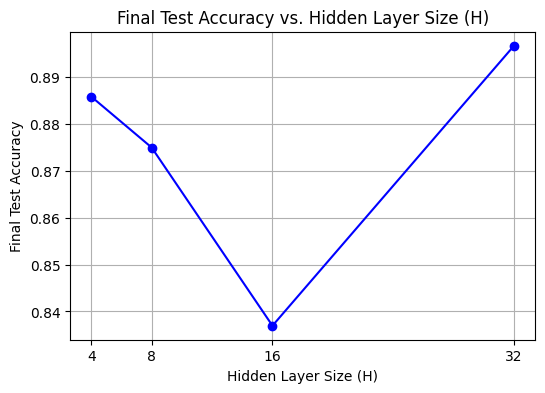

In [18]:
H_values = [4, 8, 16, 32]
final_test_accs_H = []

for H in H_values:
  print(f"For value H: {H}")
  _, _, _, _, test_accs = train_nn(X_train_s, y_train, X_test_s, y_test, num_hidden_layer=H, learning_rate=0.05, epochs=300, random_seed=42)

  final_test_accs_H.append(test_accs[-1])

plt.figure(figsize=(6, 4))
plt.plot(H_values, final_test_accs_H, marker='o', color='blue', linestyle='-')
plt.title('Final Test Accuracy vs. Hidden Layer Size (H)')
plt.xlabel('Hidden Layer Size (H)')
plt.ylabel('Final Test Accuracy')
plt.xticks(H_values)
plt.grid(True)
plt.show()

### Hidden Layer
The hidden layer size (H) determines the number of neurons in the single hidden layer of the neural network where each neuron learns to detect different patterns and features from the input data. A small hidden layer may not have enough neurons to learn complex relationships, leading to underfitting. Increasing the hidden layer size generally improves the model's ability to capture patterns, but an excessively large hidden layer may overfit the training data and increase computation time. Therefore, a larger hidden layer does not always improve test accuracy.

For value alpha: 0.001
Epoch   50 | Train Loss: 1.0140  Acc: 0.4019 | Test Loss: 0.9868  Acc: 0.3587
Epoch  100 | Train Loss: 0.9884  Acc: 0.4060 | Test Loss: 0.9693  Acc: 0.3641
Epoch  150 | Train Loss: 0.9625  Acc: 0.4169 | Test Loss: 0.9459  Acc: 0.3696
Epoch  200 | Train Loss: 0.9468  Acc: 0.4237 | Test Loss: 0.9256  Acc: 0.3804
Epoch  250 | Train Loss: 0.9266  Acc: 0.4305 | Test Loss: 0.9067  Acc: 0.3967
Epoch  300 | Train Loss: 0.9066  Acc: 0.4455 | Test Loss: 0.8874  Acc: 0.4130
For value alpha: 0.01
Epoch   50 | Train Loss: 0.8479  Acc: 0.4728 | Test Loss: 0.8265  Acc: 0.4511
Epoch  100 | Train Loss: 0.7275  Acc: 0.5572 | Test Loss: 0.6976  Acc: 0.5761
Epoch  150 | Train Loss: 0.6410  Acc: 0.6444 | Test Loss: 0.6173  Acc: 0.6522
Epoch  200 | Train Loss: 0.5780  Acc: 0.7384 | Test Loss: 0.5744  Acc: 0.7228
Epoch  250 | Train Loss: 0.5375  Acc: 0.7670 | Test Loss: 0.5352  Acc: 0.7826
Epoch  300 | Train Loss: 0.5090  Acc: 0.7834 | Test Loss: 0.5014  Acc: 0.8098
For value alpha: 0.

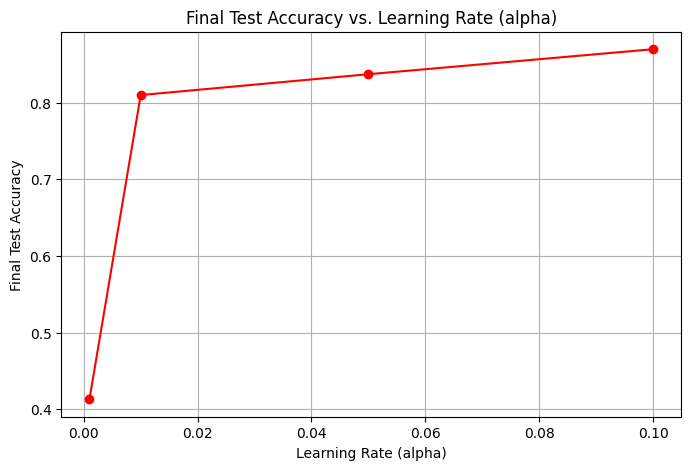

In [19]:
alpha_values = [0.001, 0.01, 0.05, 0.1]
final_test_accs_alpha = []

for alpha in alpha_values:
  print(f"For value alpha: {alpha}")
  _, _, _, _, test_accs = train_nn(X_train_s, y_train, X_test_s, y_test, num_hidden_layer=16, learning_rate=alpha, epochs=300, random_seed=42)

  final_test_accs_alpha.append(test_accs[-1])

plt.figure(figsize=(8, 5))
plt.plot(alpha_values, final_test_accs_alpha, marker='o', color='red', linestyle='-')
plt.title('Final Test Accuracy vs. Learning Rate (alpha)')
plt.xlabel('Learning Rate (alpha)')
plt.ylabel('Final Test Accuracy')
plt.grid(True)
plt.show()

## Task 03

In [20]:
def step_decay(epoch):
    if epoch < 100:
        return 0.05
    elif epoch < 200:
        return 0.005
    else:
        return 0.0005

In [21]:
W1, b1, W2, b2 = init_weights(len(X_train_s[0]), 16)

train_losses_step = []
test_losses_step = []
train_accs_step = []
test_accs_step = []

for epoch in range(300):
    lr = step_decay(epoch)

    dW1, db1, dW2, db2 = backprop(X_train_s, y_train, W1, b1, W2, b2)
    W1, b1, W2, b2 = weight_update(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate=lr)

    tr_loss = bce_loss(X_train_s, y_train, W1, b1, W2, b2)
    te_loss = bce_loss(X_test_s, y_test, W1, b1, W2, b2)
    tr_acc = calculate_accuracy(X_train_s, y_train, W1, b1, W2, b2)
    te_acc = calculate_accuracy(X_test_s, y_test, W1, b1, W2, b2)

    train_losses_step.append(tr_loss)
    test_losses_step.append(te_loss)
    train_accs_step.append(tr_acc)
    test_accs_step.append(te_acc)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:4d} | LR: {lr:.5f} | " f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | " f"Test Loss: {te_loss:.4f}  Acc: {te_acc:.4f}")

print(f"\nFinal Test Accuracy (Step Decay): {test_accs_step[-1]:.4f}")

Epoch   50 | LR: 0.05000 | Train Loss: 0.5357  Acc: 0.7698 | Test Loss: 0.5332  Acc: 0.7826
Epoch  100 | LR: 0.05000 | Train Loss: 0.4419  Acc: 0.8147 | Test Loss: 0.4393  Acc: 0.8098
Epoch  150 | LR: 0.00500 | Train Loss: 0.4381  Acc: 0.8188 | Test Loss: 0.4334  Acc: 0.8098
Epoch  200 | LR: 0.00500 | Train Loss: 0.4309  Acc: 0.8215 | Test Loss: 0.4350  Acc: 0.8098
Epoch  250 | LR: 0.00050 | Train Loss: 0.4310  Acc: 0.8202 | Test Loss: 0.4349  Acc: 0.8098
Epoch  300 | LR: 0.00050 | Train Loss: 0.4306  Acc: 0.8202 | Test Loss: 0.4348  Acc: 0.8098

Final Test Accuracy (Step Decay): 0.8098


In [22]:
def triangular_lr(epoch, total_epochs=300, min_lr=0.001, max_lr=0.1):

    half = total_epochs // 2

    if epoch <= half:
        return min_lr + (max_lr-min_lr) * epoch/half
    else:
        return max_lr - (max_lr-min_lr)*(epoch-half)/half

In [23]:
W1, b1, W2, b2 = init_weights(len(X_train_s[0]), 16)

train_losses_tri = []
test_losses_tri = []
train_accs_tri = []
test_accs_tri = []

for epoch in range(300):
    lr = triangular_lr(epoch)

    dW1, db1, dW2, db2 = backprop(X_train_s, y_train, W1, b1, W2, b2)
    W1, b1, W2, b2 = weight_update(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate=lr)

    tr_loss = bce_loss(X_train_s, y_train, W1, b1, W2, b2)
    te_loss = bce_loss(X_test_s, y_test, W1, b1, W2, b2)
    tr_acc = calculate_accuracy(X_train_s, y_train, W1, b1, W2, b2)
    te_acc = calculate_accuracy(X_test_s, y_test, W1, b1, W2, b2)

    train_losses_tri.append(tr_loss)
    test_losses_tri.append(te_loss)
    train_accs_tri.append(tr_acc)
    test_accs_tri.append(te_acc)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:4d} | LR: {lr:.5f} | " f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | " f"Test Loss: {te_loss:.4f}  Acc: {te_acc:.4f}")

print(f"\nFinal Test Accuracy (Triangular): {test_accs_tri[-1]:.4f}")

Epoch   50 | LR: 0.03334 | Train Loss: 0.7606  Acc: 0.5368 | Test Loss: 0.7219  Acc: 0.5435
Epoch  100 | LR: 0.06634 | Train Loss: 0.4920  Acc: 0.7943 | Test Loss: 0.4842  Acc: 0.8152
Epoch  150 | LR: 0.09934 | Train Loss: 0.4041  Acc: 0.8379 | Test Loss: 0.4158  Acc: 0.8098
Epoch  200 | LR: 0.06766 | Train Loss: 0.3793  Acc: 0.8529 | Test Loss: 0.3771  Acc: 0.8315
Epoch  250 | LR: 0.03466 | Train Loss: 0.3739  Acc: 0.8488 | Test Loss: 0.3737  Acc: 0.8370
Epoch  300 | LR: 0.00166 | Train Loss: 0.3728  Acc: 0.8501 | Test Loss: 0.3705  Acc: 0.8370

Final Test Accuracy (Triangular): 0.8370


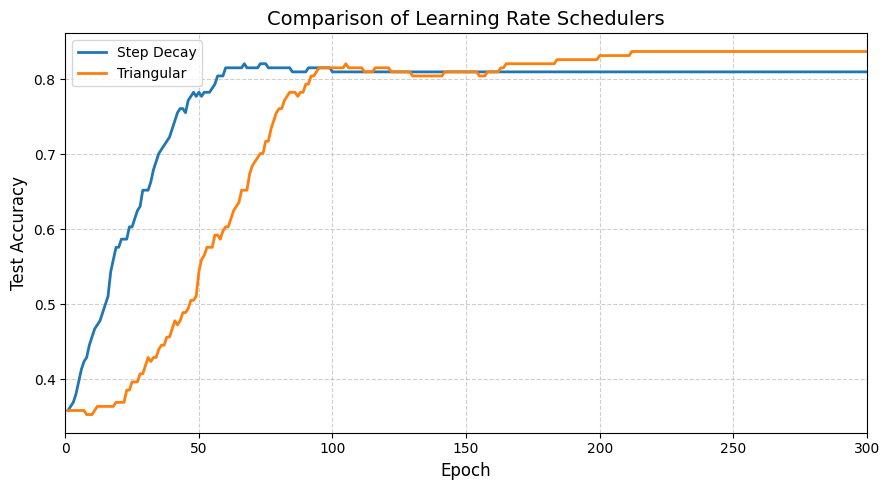

In [24]:
plt.figure(figsize=(9, 5))

epochs = range(1, 301)

plt.plot(epochs, test_accs_step, label="Step Decay", linewidth=2)

plt.plot(epochs, test_accs_tri, label="Triangular", linewidth=2)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.title("Comparison of Learning Rate Schedulers", fontsize=14)

plt.xlim(1, 300)
plt.xticks([0, 50, 100, 150, 200, 250, 300])

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

## Task 04

In [25]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

clf = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='sgd',
    learning_rate_init=0.05,
    max_iter=300,
    random_state=42
)

clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)

sk_acc = accuracy_score(y_test, y_pred)
current_acc = task1_test_accs[-1]

print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=["No Heart Disease", "Heart Disease"]))

print(f"Our Neural Network Accuracy : {current_acc:.4f}")
print(f"Scikit-Learn Accuracy       : {sk_acc:.4f}")


Classification Report
                  precision    recall  f1-score   support

No Heart Disease       0.85      0.82      0.83        82
   Heart Disease       0.86      0.88      0.87       102

        accuracy                           0.85       184
       macro avg       0.85      0.85      0.85       184
    weighted avg       0.85      0.85      0.85       184

Our Neural Network Accuracy : 0.8370
Scikit-Learn Accuracy       : 0.8533


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [26]:
batch_size = 32
epochs = 300
learning_rate = 0.05

W1, b1, W2, b2 = init_weights(len(X_train_s[0]), 16)

train_losses_mb = []
test_losses_mb = []
train_accs_mb = []
test_accs_mb = []

n_samples = len(X_train_s)

for epoch in range(epochs):
    indices = np.arange(n_samples)
    np.random.shuffle(indices)

    for start in range(0, n_samples, batch_size):
        batch = indices[start:start + batch_size]

        X_batch = X_train_s[batch].tolist()
        y_batch = y_train[batch].tolist()

        dW1, db1, dW2, db2 = backprop(X_batch, y_batch, W1, b1, W2, b2)

        W1, b1, W2, b2 = weight_update(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate)

    tr_loss = bce_loss(X_train_s, y_train, W1, b1, W2, b2)
    te_loss = bce_loss(X_test_s, y_test, W1, b1, W2, b2)

    tr_acc = calculate_accuracy(X_train_s, y_train, W1, b1, W2, b2)
    te_acc = calculate_accuracy(X_test_s, y_test, W1, b1, W2, b2)

    train_losses_mb.append(tr_loss)
    test_losses_mb.append(te_loss)

    train_accs_mb.append(tr_acc)
    test_accs_mb.append(te_acc)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:4d} | " f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | " f"Test Loss: {te_loss:.4f}  Acc: {te_acc:.4f}")

print(f"\nFinal Test Accuracy (Mini-Batch): {test_accs_mb[-1]:.4f}")

Epoch   50 | Train Loss: 0.3578  Acc: 0.8556 | Test Loss: 0.3333  Acc: 0.9022
Epoch  100 | Train Loss: 0.3483  Acc: 0.8638 | Test Loss: 0.3556  Acc: 0.8696
Epoch  150 | Train Loss: 0.3478  Acc: 0.8597 | Test Loss: 0.3546  Acc: 0.8804
Epoch  200 | Train Loss: 0.3525  Acc: 0.8610 | Test Loss: 0.3653  Acc: 0.8641
Epoch  250 | Train Loss: 0.3524  Acc: 0.8569 | Test Loss: 0.3734  Acc: 0.8641
Epoch  300 | Train Loss: 0.3532  Acc: 0.8569 | Test Loss: 0.3716  Acc: 0.8587

Final Test Accuracy (Mini-Batch): 0.8587


In [27]:
def epoch_to_accuracy(accs, target=0.85):
    for i, acc in enumerate(accs):
        if acc >= target:
            return i + 1
    return "Not Reached"

epochs_full = epoch_to_accuracy(test_accs)
epochs_mb = epoch_to_accuracy(test_accs_mb)

print("\nConvergence Comparison")
print(f"Full Batch : {epochs_full} epochs to reach 85% accuracy")
print(f"Mini Batch : {epochs_mb} epochs to reach 85% accuracy")


Convergence Comparison
Full Batch : 217 epochs to reach 85% accuracy
Mini Batch : 19 epochs to reach 85% accuracy


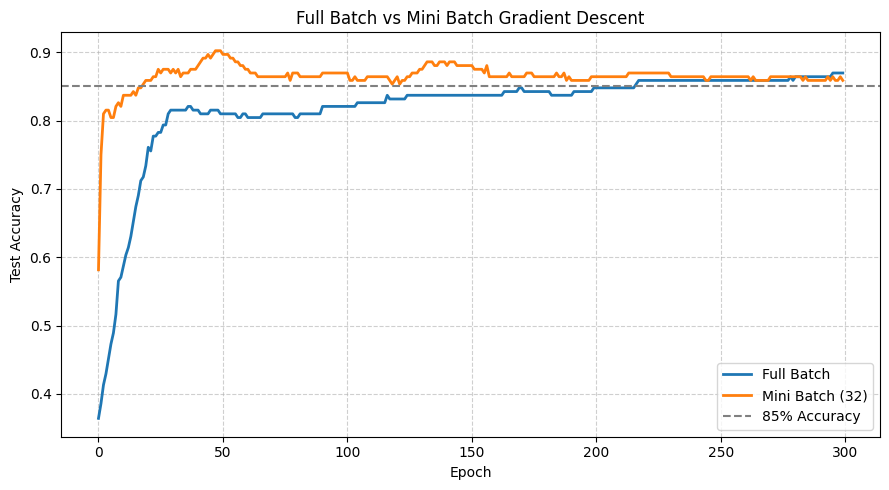

In [28]:
plt.figure(figsize=(9,5))

plt.plot(test_accs, label="Full Batch", linewidth=2)

plt.plot(test_accs_mb, label="Mini Batch (32)", linewidth=2)

plt.axhline(0.85, linestyle="--", color="gray", label="85% Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("Full Batch vs Mini Batch Gradient Descent")

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()